In [ ]:
import sys
import tensorflow as tf

# Display Python and TensorFlow versions
print("Python version:", sys.version)
print("TensorFlow version:", tf.__version__)

# Check whether a GPU is available
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("Success: GPU detected.")
    print("Available GPUs:", gpus)
else:
    print("No GPU detected.")
    print()

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
TensorFlow version: 2.21.0
Success: GPU detected.
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from pathlib import Path
import shutil
import zipfile

REPO_DIR = Path("/content/handwriting_data_all")
ZIP_PATH = Path("/content/all_data.zip")

# Define all 12 archive parts in the correct order.
parts = [
    REPO_DIR / f"all_data.zip.{i:03d}"
    for i in range(1, 13)
]

missing_parts = [path.name for path in parts if not path.is_file()]

if missing_parts:
    print("STOP: Some archive parts are missing.")
    print("Run the dataset download cell above, then run this cell again.")
    print("\nMissing parts:")
    for name in missing_parts:
        print(name)

elif any(path.stat().st_size < 1024 for path in parts):
    print("STOP: An archive part is unexpectedly small.")
    print("Please share this output before continuing.")

else:
    # Combine the numbered parts into one ZIP archive.
    print("Combining archive parts...")

    with ZIP_PATH.open("wb") as output_file:
        for part in parts:
            with part.open("rb") as input_file:
                shutil.copyfileobj(
                    input_file,
                    output_file,
                    length=1024 * 1024
                )

    size_gb = ZIP_PATH.stat().st_size / (1024 ** 3)
    print(f"Combined archive size: {size_gb:.2f} GB")

    # Inspect filenames using the encoding specified by the dataset.
    with zipfile.ZipFile(
        ZIP_PATH, mode="r", metadata_encoding="big5"
    ) as archive:
        files = [
            info for info in archive.infolist()
            if not info.is_dir()
        ]

        image_extensions = {
            ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"
        }

        images = [
            info for info in files
            if Path(info.filename).suffix.lower() in image_extensions
            and "__MACOSX" not in Path(info.filename).parts
            and not Path(info.filename).name.startswith("._")
        ]

        print(f"File entries: {len(files):,}")
        print(f"Image entries: {len(images):,}")

        unpacked_gb = sum(
            info.file_size for info in files
        ) / (1024 ** 3)
        print(f"Uncompressed file size: {unpacked_gb:.2f} GB")

        print("\nFirst 15 image paths:")
        for info in images[:15]:
            print(info.filename)

    print("\nArchive inspection complete. No files have been extracted.")

STOP: Some archive parts are missing.
Run the dataset download cell above, then run this cell again.

Missing parts:
all_data.zip.001
all_data.zip.002
all_data.zip.003
all_data.zip.004
all_data.zip.005
all_data.zip.006
all_data.zip.007
all_data.zip.008
all_data.zip.009
all_data.zip.010
all_data.zip.011
all_data.zip.012


In [ ]:
from pathlib import Path
import subprocess

REPO_URL = "https://github.com/chenkenanalytic/handwriting_data_all.git"
REPO_DIR = Path("/content/handwriting_data_all")

# Check whether a previous download left any files.
print("=== Local folder check ===")

if REPO_DIR.exists():
    print("Dataset folder exists.")
    items = sorted(REPO_DIR.iterdir())
    print(f"Items found: {len(items)}")

    for path in items[:20]:
        print(path.name)
else:
    print("Dataset folder does not exist.")

# Test access to the repository without downloading the dataset.
print("\n=== GitHub connection check ===", flush=True)

try:
    result = subprocess.run(
        ["git", "ls-remote", REPO_URL, "HEAD"],
        capture_output=True,
        text=True,
        timeout=60,
        env={
            **__import__("os").environ,
            "GIT_TERMINAL_PROMPT": "0"
        }
    )

    print("Exit code:", result.returncode)
    print("Output:")
    print(result.stdout.strip() or "(empty)")
    print("Error details:")
    print(result.stderr.strip() or "(none)")

except subprocess.TimeoutExpired:
    print("Connection timed out after 60 seconds.")

=== Local folder check ===
Dataset folder does not exist.

=== GitHub connection check ===
Exit code: 128
Output:
(empty)
Error details:
fatal: could not read Username for 'https://github.com': terminal prompts disabled


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path
import shutil

SOURCE_DIR = Path("/content/drive/MyDrive/DIT5411_dataset")
TARGET_DIR = Path("/content/handwriting_data_all")

expected_names = [
    f"all_data.zip.{i:03d}"
    for i in range(1, 13)
]

# Check that all uploaded parts exist before copying.
missing = [
    name for name in expected_names
    if not (SOURCE_DIR / name).is_file()
]

if missing:
    print("STOP: Some files are missing from Google Drive.")
    print("Expected folder:", SOURCE_DIR)

    for name in missing:
        print("MISSING:", name)

    print("\nWait for all uploads to finish and check the folder name.")

else:
    small_files = [
        name for name in expected_names
        if (SOURCE_DIR / name).stat().st_size < 1024
    ]

    if small_files:
        print("STOP: Some files are unexpectedly small.")
        for name in small_files:
            print(name)

    else:
        TARGET_DIR.mkdir(parents=True, exist_ok=True)

        print("Copying archive parts to Colab...", flush=True)

        for name in expected_names:
            source = SOURCE_DIR / name
            target = TARGET_DIR / name

            shutil.copy2(source, target)

            size_mb = target.stat().st_size / (1024 ** 2)
            print(f"Copied: {name} ({size_mb:.2f} MB)", flush=True)

        print("\nSuccess: All 12 archive parts are available in Colab.")

Copying archive parts to Colab...
Copied: all_data.zip.001 (95.00 MB)
Copied: all_data.zip.002 (95.00 MB)
Copied: all_data.zip.003 (95.00 MB)
Copied: all_data.zip.004 (95.00 MB)
Copied: all_data.zip.005 (95.00 MB)
Copied: all_data.zip.006 (95.00 MB)
Copied: all_data.zip.007 (95.00 MB)
Copied: all_data.zip.008 (95.00 MB)
Copied: all_data.zip.009 (95.00 MB)
Copied: all_data.zip.010 (95.00 MB)
Copied: all_data.zip.011 (95.00 MB)
Copied: all_data.zip.012 (42.28 MB)

Success: All 12 archive parts are available in Colab.


In [ ]:
from pathlib import Path
import zipfile

ZIP_PATH = Path("/content/all_data.zip")

if not ZIP_PATH.is_file():
    raise FileNotFoundError(
        "The combined ZIP file is missing. Run the merge cell first."
    )

print("Reading archive filenames with CP950...", flush=True)

try:
    with zipfile.ZipFile(
        ZIP_PATH, mode="r", metadata_encoding="cp950"
    ) as archive:
        files = [
            info for info in archive.infolist()
            if not info.is_dir()
        ]

        image_extensions = {
            ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"
        }

        images = [
            info for info in files
            if Path(info.filename).suffix.lower() in image_extensions
            and "__MACOSX" not in Path(info.filename).parts
            and not Path(info.filename).name.startswith("._")
        ]

        total_bytes = sum(info.file_size for info in files)

        print("Filename encoding: cp950")
        print(f"File entries: {len(files):,}")
        print(f"Image entries: {len(images):,}")
        print(
            f"Uncompressed file size: "
            f"{total_bytes / (1024 ** 3):.2f} GB"
        )

        print("\nFirst 20 image paths:")
        for info in images[:20]:
            print(info.filename)

    print("\nArchive inspection complete.")
    print("No files have been extracted.")
    print("Image integrity has not been checked yet.")

except UnicodeDecodeError as error:
    print("\nSTOP: CP950 could not decode all filenames.")
    print(error)
    print("Please share this output before continuing.")

except zipfile.BadZipFile as error:
    print("\nSTOP: The ZIP archive could not be read.")
    print(error)
    print("Please share this output before continuing.")

Reading archive filenames with CP950...
Filename encoding: cp950
File entries: 684,677
Image entries: 684,677
Uncompressed file size: 1.18 GB

First 20 image paths:
cleaned_data/10000/颮_0.png
cleaned_data/10000/颮_1.png
cleaned_data/10000/颮_10.png
cleaned_data/10000/颮_11.png
cleaned_data/10000/颮_12.png
cleaned_data/10000/颮_13.png
cleaned_data/10000/颮_14.png
cleaned_data/10000/颮_15.png
cleaned_data/10000/颮_16.png
cleaned_data/10000/颮_17.png
cleaned_data/10000/颮_18.png
cleaned_data/10000/颮_19.png
cleaned_data/10000/颮_2.png
cleaned_data/10000/颮_20.png
cleaned_data/10000/颮_21.png
cleaned_data/10000/颮_22.png
cleaned_data/10000/颮_23.png
cleaned_data/10000/颮_24.png
cleaned_data/10000/颮_25.png
cleaned_data/10000/颮_26.png

Archive inspection complete.
No files have been extracted.
Image integrity has not been checked yet.


PNG images: 684,677
Image folders: 13,065
Unique filename labels: 13,065
Folders with multiple labels: 0
Labels appearing in multiple folders: 0
Minimum images per folder: 16
Maximum images per folder: 61

PASS: The folder-label structure matches 13,065 classes.

Preview samples:
cleaned_data/1/一_0.png | size=(300, 300) | mode=RGB
cleaned_data/11958/嬯_0.png | size=(300, 300) | mode=RGB
cleaned_data/2159/汜_0.png | size=(300, 300) | mode=RGB
cleaned_data/4118/光_0.png | size=(300, 300) | mode=RGB
cleaned_data/6079/膻_0.png | size=(300, 300) | mode=RGB
cleaned_data/8038/謷_0.png | size=(300, 300) | mode=RGB


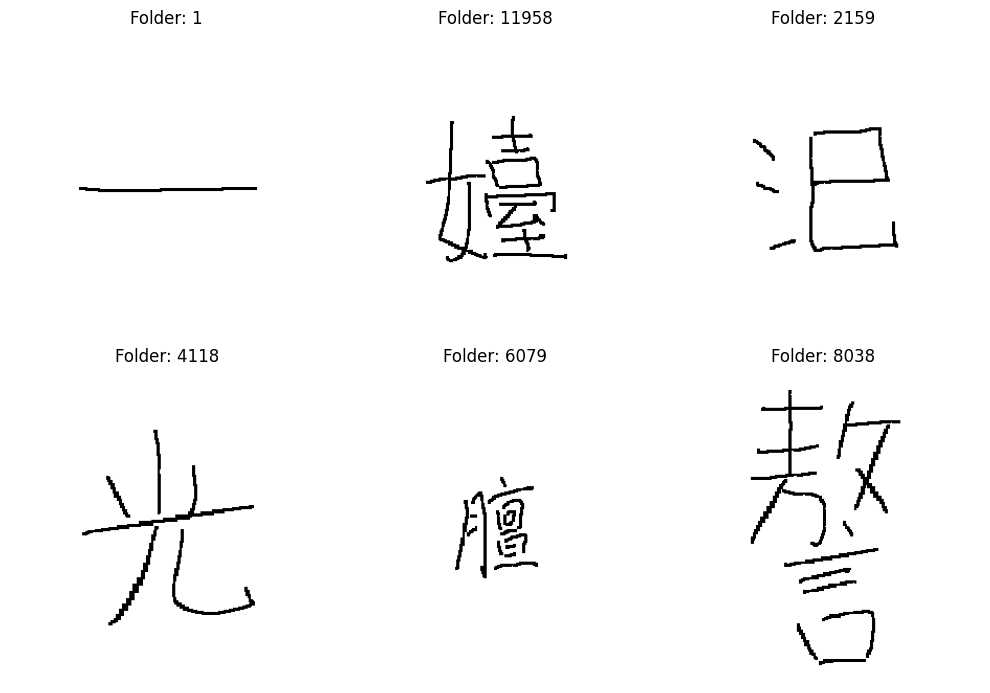


Only the preview images were decoded, not the entire dataset.


In [ ]:
from pathlib import Path, PurePosixPath
from collections import defaultdict, Counter
from io import BytesIO
import zipfile
import matplotlib.pyplot as plt
from PIL import Image

ZIP_PATH = Path("/content/all_data.zip")

with zipfile.ZipFile(
    ZIP_PATH, mode="r", metadata_encoding="cp950"
) as archive:

    # Group PNG images by their parent folder.
    groups = defaultdict(list)
    labels_by_folder = defaultdict(set)

    for info in archive.infolist():
        path = PurePosixPath(info.filename)

        if (
            info.is_dir()
            or path.suffix.lower() != ".png"
            or "__MACOSX" in path.parts
            or path.name.startswith("._")
        ):
            continue

        folder = str(path.parent)
        label = path.stem.rsplit("_", 1)[0]

        groups[folder].append(info)
        labels_by_folder[folder].add(label)

    if not groups:
        raise RuntimeError("No PNG images were found.")

    counts = [len(items) for items in groups.values()]
    unique_labels = set().union(*labels_by_folder.values())

    mixed_folders = {
        folder: labels
        for folder, labels in labels_by_folder.items()
        if len(labels) != 1
    }

    label_folder_counts = Counter(
        label
        for labels in labels_by_folder.values()
        for label in labels
    )
    repeated_labels = {
        label: count
        for label, count in label_folder_counts.items()
        if count > 1
    }

    print(f"PNG images: {sum(counts):,}")
    print(f"Image folders: {len(groups):,}")
    print(f"Unique filename labels: {len(unique_labels):,}")
    print(f"Folders with multiple labels: {len(mixed_folders):,}")
    print(f"Labels appearing in multiple folders: {len(repeated_labels):,}")
    print(f"Minimum images per folder: {min(counts)}")
    print(f"Maximum images per folder: {max(counts)}")

    if (
        len(groups) == 13065
        and len(unique_labels) == 13065
        and not mixed_folders
        and not repeated_labels
    ):
        print("\nPASS: The folder-label structure matches 13,065 classes.")
    else:
        print("\nCHECK: Review the class structure before training.")

    # Preview one image from each of six different folders.
    folders = sorted(groups)
    sample_count = min(6, len(folders))
    fig, axes = plt.subplots(2, 3, figsize=(10, 7))
    axes = axes.ravel()

    print("\nPreview samples:")

    for index, ax in enumerate(axes):
        ax.axis("off")

        if index >= sample_count:
            continue

        folder_index = index * len(folders) // sample_count
        folder = folders[folder_index]
        info = groups[folder][0]

        # Reading an entry also checks its ZIP CRC.
        with Image.open(BytesIO(archive.read(info))) as image:
            image.load()
            print(
                f"{info.filename} | "
                f"size={image.size} | mode={image.mode}"
            )
            ax.imshow(image.convert("L"), cmap="gray")
            ax.set_title(f"Folder: {PurePosixPath(folder).name}")

    plt.tight_layout()
    plt.show()

print("\nOnly the preview images were decoded, not the entire dataset.")

In [ ]:
from pathlib import Path
import shutil
import zipfile
from tqdm.auto import tqdm

ZIP_PATH = Path("/content/all_data.zip")
OUTPUT_DIR = Path("/content/handwriting_dataset")

if not ZIP_PATH.is_file():
    raise FileNotFoundError("The combined ZIP file is missing.")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
output_root = OUTPUT_DIR.resolve()

with zipfile.ZipFile(
    ZIP_PATH, mode="r", metadata_encoding="cp950"
) as archive:
    images = [
        info for info in archive.infolist()
        if not info.is_dir()
        and Path(info.filename).suffix.lower() == ".png"
        and "__MACOSX" not in Path(info.filename).parts
        and not Path(info.filename).name.startswith("._")
    ]

    if not images:
        raise RuntimeError("No PNG images were found.")

    # Check all destination paths before extracting.
    for info in images:
        destination = (OUTPUT_DIR / info.filename).resolve()

        if not destination.is_relative_to(output_root):
            raise RuntimeError(
                f"Unsafe archive path: {info.filename}"
            )

    required_bytes = sum(info.file_size for info in images)
    free_bytes = shutil.disk_usage(OUTPUT_DIR).free
    extra_space = 5 * 1024 ** 3

    print(f"Images to extract: {len(images):,}")
    print(f"Free disk space: {free_bytes / (1024 ** 3):.2f} GB")

    if free_bytes < required_bytes + extra_space:
        raise RuntimeError(
            "Not enough free disk space for extraction plus a safety margin."
        )

    # Reading each entry during extraction checks its ZIP CRC.
    # Rerunning this cell overwrites files with the same names.
    for info in tqdm(images, desc="Extracting images", unit="image"):
        archive.extract(info, path=OUTPUT_DIR)

DATA_DIR = OUTPUT_DIR / "cleaned_data"

if not DATA_DIR.is_dir():
    raise RuntimeError(
        "The expected cleaned_data folder was not found."
    )

folder_count = sum(
    1 for path in DATA_DIR.iterdir()
    if path.is_dir()
)

print("\nExtraction complete.")
print("Dataset folder:", DATA_DIR)
print(f"Top-level class folders: {folder_count:,}")
print("PNG archive entries were extracted and passed ZIP CRC checks.")
print("Full image decoding has not been checked yet.")

Images to extract: 684,677
Free disk space: 104.42 GB


Extracting images:   0%|          | 0/684677 [00:00<?, ?image/s]


Extraction complete.
Dataset folder: /content/handwriting_dataset/cleaned_data
Top-level class folders: 13,065
PNG archive entries were extracted and passed ZIP CRC checks.
Full image decoding has not been checked yet.


In [ ]:
from pathlib import Path
from collections import Counter
import csv
import re

DATA_DIR = Path("/content/handwriting_dataset/cleaned_data")
REPORT_PATH = Path("/content/class_sample_audit.csv")

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        "Dataset folder not found. Restore and extract the dataset first."
    )

class_dirs = sorted(
    [path for path in DATA_DIR.iterdir() if path.is_dir()],
    key=lambda path: (
        0, int(path.name)
    ) if path.name.isdigit() else (
        1, path.name
    )
)

rows = []
invalid_names = []
duplicate_ids = []
preview = []

for folder in class_dirs:
    images = [
        path for path in folder.iterdir()
        if path.is_file() and path.suffix.lower() == ".png"
    ]

    parsed = []

    for path in images:
        match = re.fullmatch(r"(.+)_(\d+)", path.stem)

        if match is None:
            invalid_names.append(str(path))
            continue

        label = match.group(1)
        sample_id = int(match.group(2))
        parsed.append((sample_id, label, path))

    parsed.sort(key=lambda item: (item[0], item[2].name))

    labels = sorted({item[1] for item in parsed})
    id_counts = Counter(item[0] for item in parsed)
    repeated = [
        sample_id for sample_id, count in id_counts.items()
        if count > 1
    ]

    if repeated:
        duplicate_ids.append((folder.name, repeated))

    count = len(images)

    rows.append({
        "folder": folder.name,
        "label": "|".join(labels),
        "image_count": count,
        "parsed_count": len(parsed),
        "label_count": len(labels),
        "training_count_under_first40": min(40, count),
        "testing_count_under_first40": max(0, count - 40),
        "status": (
            "below_40" if count < 40
            else "exactly_40" if count == 40
            else "above_40"
        )
    })

    if len(preview) < 2:
        preview.append((
            folder.name,
            [item[2].name for item in parsed[:45]]
        ))

if not rows:
    raise RuntimeError("No class folders were found.")

# Save a report without modifying any source images.
with REPORT_PATH.open(
    "w", newline="", encoding="utf-8-sig"
) as file:
    writer = csv.DictWriter(file, fieldnames=list(rows[0].keys()))
    writer.writeheader()
    writer.writerows(rows)

below_40 = [row for row in rows if row["image_count"] < 40]
exactly_40 = [row for row in rows if row["image_count"] == 40]
above_40 = [row for row in rows if row["image_count"] > 40]
invalid_classes = [
    row for row in rows
    if row["label_count"] != 1
    or row["parsed_count"] != row["image_count"]
]

print("=== Dataset audit ===")
print(f"Class folders: {len(rows):,}")
print(f"Total PNG images: {sum(row['image_count'] for row in rows):,}")
print(f"Classes with fewer than 40 images: {len(below_40):,}")
print(f"Classes with exactly 40 images: {len(exactly_40):,}")
print(f"Classes with more than 40 images: {len(above_40):,}")
print(f"Invalid filename patterns: {len(invalid_names):,}")
print(f"Classes with parsing or label issues: {len(invalid_classes):,}")
print(f"Classes with duplicate sample IDs: {len(duplicate_ids):,}")

print("\n=== Image count distribution ===")
distribution = Counter(row["image_count"] for row in rows)

for image_count, class_count in sorted(distribution.items()):
    print(f"{image_count} images: {class_count} classes")

print("\n=== First 20 classes with 40 or fewer images ===")
limited_classes = [
    row for row in rows if row["image_count"] <= 40
]

for row in limited_classes[:20]:
    print(
        f"Folder={row['folder']} | "
        f"Label={row['label']} | "
        f"Images={row['image_count']}"
    )

print("\n=== Numeric filename ordering preview ===")
for folder_name, names in preview:
    print(f"Folder {folder_name}:")
    print(", ".join(names))

if invalid_names:
    print("\nFirst invalid filenames:")
    for name in invalid_names[:10]:
        print(name)

if duplicate_ids:
    print("\nFirst duplicate sample ID cases:")
    for item in duplicate_ids[:10]:
        print(item)

print("\nAudit report saved to:", REPORT_PATH)
print("No dataset split or augmentation has been performed.")

=== Dataset audit ===
Class folders: 13,065
Total PNG images: 684,677
Classes with fewer than 40 images: 43
Classes with exactly 40 images: 0
Classes with more than 40 images: 13,022
Invalid filename patterns: 0
Classes with parsing or label issues: 0
Classes with duplicate sample IDs: 0

=== Image count distribution ===
16 images: 1 classes
17 images: 1 classes
18 images: 2 classes
20 images: 4 classes
21 images: 1 classes
22 images: 2 classes
23 images: 3 classes
27 images: 1 classes
31 images: 2 classes
32 images: 9 classes
33 images: 2 classes
34 images: 8 classes
35 images: 4 classes
36 images: 2 classes
37 images: 1 classes
47 images: 1 classes
48 images: 5 classes
49 images: 1915 classes
50 images: 2742 classes
51 images: 4426 classes
52 images: 600 classes
53 images: 106 classes
56 images: 2 classes
57 images: 122 classes
58 images: 1079 classes
59 images: 1429 classes
60 images: 590 classes
61 images: 5 classes

=== First 20 classes with 40 or fewer images ===
Folder=23 | Labe

In [ ]:
from pathlib import Path
from collections import Counter
import csv
from PIL import Image
from tqdm.auto import tqdm

DATA_DIR = Path("/content/handwriting_dataset/cleaned_data")
REPORT_DIR = Path("/content/dataset_reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_DIR.is_dir():
    raise FileNotFoundError("The extracted dataset folder is missing.")

image_paths = sorted(DATA_DIR.rglob("*.png"))

if not image_paths:
    raise RuntimeError("No PNG images were found.")

size_counts = Counter()
mode_counts = Counter()
issues = []

print(f"Images to check: {len(image_paths):,}", flush=True)

for path in tqdm(image_paths, desc="Checking images", unit="image"):
    try:
        with Image.open(path) as image:
            # Decode all pixel data, not just the image header.
            image.load()

            # Check the grayscale conversion planned for preprocessing.
            grayscale = image.convert("L")
            grayscale.load()

            size_counts[image.size] += 1
            mode_counts[image.mode] += 1

    except Exception as error:
        issues.append({
            "relative_path": path.relative_to(DATA_DIR).as_posix(),
            "error": f"{type(error).__name__}: {error}"
        })

issue_report = REPORT_DIR / "image_decode_issues.csv"

with issue_report.open(
    "w", newline="", encoding="utf-8-sig"
) as file:
    writer = csv.DictWriter(
        file,
        fieldnames=["relative_path", "error"]
    )
    writer.writeheader()
    writer.writerows(issues)

summary_lines = [
    f"Total images checked: {len(image_paths):,}",
    f"Successfully decoded: {len(image_paths) - len(issues):,}",
    f"Failed images: {len(issues):,}",
    "",
    "Image sizes:"
]

for size, count in sorted(size_counts.items()):
    summary_lines.append(f"{size}: {count:,}")

summary_lines.append("")
summary_lines.append("Image modes:")

for mode, count in sorted(mode_counts.items()):
    summary_lines.append(f"{mode}: {count:,}")

summary = "\n".join(summary_lines)

summary_path = REPORT_DIR / "image_decode_summary.txt"
summary_path.write_text(summary, encoding="utf-8")

print("\n" + summary)
print("\nIssue report:", issue_report)
print("Summary report:", summary_path)

if issues:
    print("\nSTOP: Review failed images before preparing training data.")
    for issue in issues[:10]:
        print(issue)
else:
    print("\nPASS: All PNG images decoded successfully.")

print("No source images were modified or deleted.")

Images to check: 684,677


Checking images:   0%|          | 0/684677 [00:00<?, ?image/s]


Total images checked: 684,677
Successfully decoded: 684,677
Failed images: 0

Image sizes:
(300, 300): 684,677

Image modes:
RGB: 684,677

Issue report: /content/dataset_reports/image_decode_issues.csv
Summary report: /content/dataset_reports/image_decode_summary.txt

PASS: All PNG images decoded successfully.
No source images were modified or deleted.


In [ ]:
from pathlib import Path
import zipfile
from google.colab import files

report_paths = [
    Path("/content/class_sample_audit.csv"),
    Path("/content/dataset_reports/image_decode_issues.csv"),
    Path("/content/dataset_reports/image_decode_summary.txt")
]

missing = [str(path) for path in report_paths if not path.is_file()]
if missing:
    raise FileNotFoundError("Missing reports: " + ", ".join(missing))

backup_path = Path("/content/dataset_audit_reports.zip")

with zipfile.ZipFile(
    backup_path, mode="w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in report_paths:
        archive.write(path, arcname=path.name)

print("Report backup created:", backup_path)
files.download(str(backup_path))

Report backup created: /content/dataset_audit_reports.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sys
import shutil
import subprocess
from pathlib import Path

print("Python version:", sys.version.split()[0])

try:
    import tensorflow as tf

    print("TensorFlow version:", tf.__version__)

    gpus = tf.config.list_physical_devices("GPU")
    print("TensorFlow GPU count:", len(gpus))

    for gpu in gpus:
        details = tf.config.experimental.get_device_details(gpu)
        print("GPU:", details.get("device_name", gpu.name))

    if not gpus:
        print("No GPU is currently available to TensorFlow.")

except ImportError as error:
    print("TensorFlow import failed:", error)

if shutil.which("nvidia-smi"):
    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=name,memory.total,memory.free",
            "--format=csv"
        ],
        capture_output=True,
        text=True
    )
    print("\nNVIDIA GPU status:")
    print(result.stdout or result.stderr)

data_dir = Path("/content/handwriting_dataset/cleaned_data")
print("\nDataset folder exists:", data_dir.is_dir())

disk = shutil.disk_usage("/content")
print(f"Free disk space: {disk.free / (1024 ** 3):.2f} GB")

Python version: 3.13.18
TensorFlow version: 2.21.0
TensorFlow GPU count: 0
No GPU is currently available to TensorFlow.

Dataset folder exists: True
Free disk space: 101.76 GB


In [ ]:
from pathlib import Path

paths = {
    "Extracted dataset": Path(
        "/content/handwriting_dataset/cleaned_data"
    ),
    "Combined ZIP": Path("/content/all_data.zip"),
    "Class audit report": Path("/content/class_sample_audit.csv"),
    "Image check report": Path(
        "/content/dataset_reports/image_decode_summary.txt"
    ),
}

for name, path in paths.items():
    print(f"{name}: {path.exists()}")

Extracted dataset: True
Combined ZIP: True
Class audit report: True
Image check report: True


Mapped classes: 13,065
Class ID range: 0 to 13064
Mapping saved to: /content/DIT5411_project/class_mapping.json


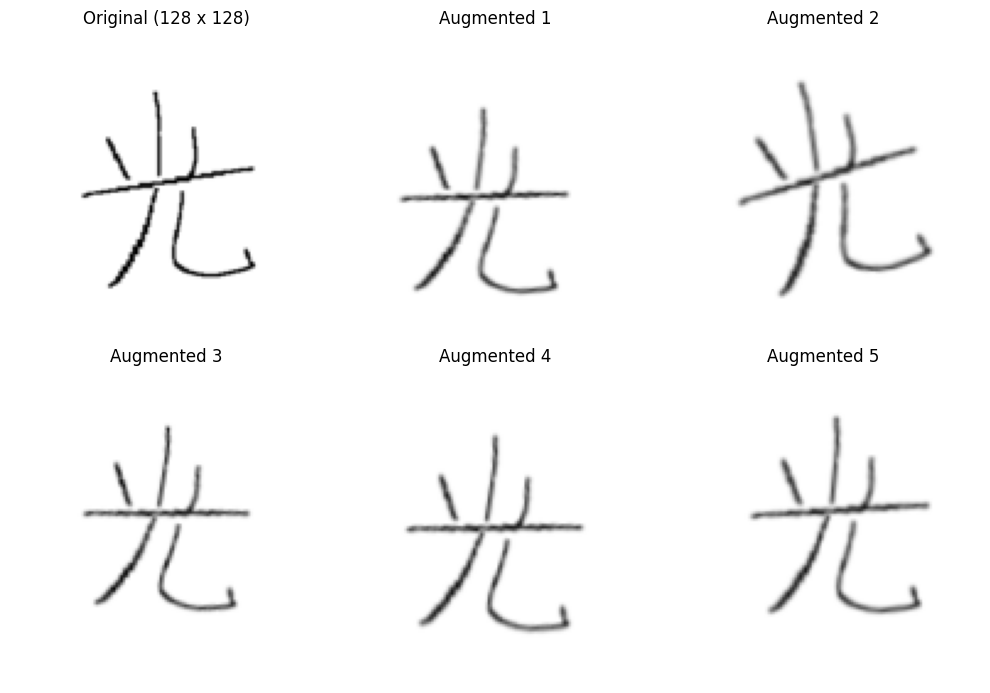


Source image: 4118/光_0.png
Preview saved to: /content/DIT5411_project/augmentation_preview.png
No source images were modified.
No training/test split has been created.


In [ ]:
from pathlib import Path
import csv
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path("/content/handwriting_dataset/cleaned_data")
AUDIT_PATH = Path("/content/class_sample_audit.csv")
PROJECT_DIR = Path("/content/DIT5411_project")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

# Build a stable class mapping from the existing audit.
with AUDIT_PATH.open(encoding="utf-8-sig", newline="") as file:
    rows = list(csv.DictReader(file))

rows.sort(key=lambda row: int(row["folder"]))

if len(rows) != 13065:
    raise RuntimeError("Expected exactly 13,065 classes.")

if any(
    int(row["label_count"]) != 1
    or int(row["parsed_count"]) != int(row["image_count"])
    for row in rows
):
    raise RuntimeError("The class audit contains unresolved issues.")

if len({row["label"] for row in rows}) != 13065:
    raise RuntimeError("Character labels are not unique.")

class_mapping = [
    {
        "class_id": class_id,
        "folder": row["folder"],
        "character": row["label"]
    }
    for class_id, row in enumerate(rows)
]

mapping_path = PROJECT_DIR / "class_mapping.json"
mapping_path.write_text(
    json.dumps(class_mapping, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print(f"Mapped classes: {len(class_mapping):,}")
print("Class ID range: 0 to 13064")
print("Mapping saved to:", mapping_path)

# Preview a multi-stroke character if the folder is available.
preview_folder = DATA_DIR / "4118"
if not preview_folder.is_dir():
    preview_folder = DATA_DIR / rows[0]["folder"]

paths = sorted(
    preview_folder.glob("*.png"),
    key=lambda path: int(path.stem.rsplit("_", 1)[1])
)

if not paths:
    raise RuntimeError("No preview image was found.")

source_path = paths[0]

# Use grayscale and an initial 128 x 128 input size.
# Keep white as 1.0 and black as 0.0.
with Image.open(source_path) as image:
    array = np.array(image.convert("L"), dtype=np.float32) / 255.0

original = tf.image.resize(
    array[..., None],
    size=(128, 128),
    method="bilinear",
    antialias=True
)

# Conservative transformations; no horizontal or vertical flips.
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(
        factor=0.025,  # Approximately -9 to +9 degrees.
        fill_mode="constant",
        fill_value=1.0,
        seed=101
    ),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode="constant",
        fill_value=1.0,
        seed=102
    ),
    tf.keras.layers.RandomZoom(
        height_factor=(-0.08, 0.08),
        width_factor=None,
        fill_mode="constant",
        fill_value=1.0,
        seed=103
    )
], name="training_augmentation")

batch = tf.repeat(original[None, ...], repeats=5, axis=0)
variants = augmentation(batch, training=True).numpy()

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
preview_images = [original.numpy(), *variants]

for index, (ax, image) in enumerate(zip(axes.ravel(), preview_images)):
    ax.imshow(image[..., 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title("Original (128 x 128)" if index == 0
                 else f"Augmented {index}")
    ax.axis("off")

plt.tight_layout()

preview_path = PROJECT_DIR / "augmentation_preview.png"
fig.savefig(preview_path, dpi=150, bbox_inches="tight")
plt.show()

print("\nSource image:", source_path.relative_to(DATA_DIR))
print("Preview saved to:", preview_path)
print("No source images were modified.")
print("No training/test split has been created.")

In [ ]:
from pathlib import Path
import json
import numpy as np
import tensorflow as tf
from PIL import Image

PROJECT_DIR = Path("/content/DIT5411_project")
DATA_DIR = Path("/content/handwriting_dataset/cleaned_data")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

mapping_path = PROJECT_DIR / "class_mapping.json"
class_mapping = json.loads(
    mapping_path.read_text(encoding="utf-8")
)

NUM_CLASSES = len(class_mapping)
IMAGE_SIZE = 128

if NUM_CLASSES != 13065:
    raise RuntimeError("Expected 13,065 output classes.")

tf.keras.utils.set_random_seed(2026)

def build_baseline_cnn(num_classes=13065):
    inputs = tf.keras.Input(
        shape=(IMAGE_SIZE, IMAGE_SIZE, 1),
        name="grayscale_image"
    )

    x = inputs

    for block_id, filters in enumerate([16, 32, 64, 128], start=1):
        x = tf.keras.layers.Conv2D(
            filters,
            kernel_size=3,
            padding="same",
            activation="relu",
            name=f"conv_{block_id}"
        )(x)

        x = tf.keras.layers.MaxPooling2D(
            pool_size=2,
            name=f"pool_{block_id}"
        )(x)

    x = tf.keras.layers.Flatten(name="flatten")(x)
    x = tf.keras.layers.Dense(
        256, activation="relu", name="dense_features"
    )(x)
    x = tf.keras.layers.Dropout(0.4, name="dropout")(x)

    outputs = tf.keras.layers.Dense(
        num_classes,
        activation="softmax",
        dtype="float32",
        name="character_probabilities"
    )(x)

    return tf.keras.Model(inputs, outputs, name="baseline_cnn")


model = build_baseline_cnn(NUM_CLASSES)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5, name="top5_accuracy"
        )
    ]
)

model.summary()

# Load one image solely to test the forward pass.
sample_folder = DATA_DIR / class_mapping[0]["folder"]

sample_paths = sorted(
    sample_folder.glob("*.png"),
    key=lambda path: int(path.stem.rsplit("_", 1)[1])
)

if not sample_paths:
    raise RuntimeError("No image was found for the smoke test.")

sample_path = sample_paths[0]

with Image.open(sample_path) as image:
    array = np.array(image.convert("L"), dtype=np.float32) / 255.0

image_tensor = tf.image.resize(
    array[..., None],
    (IMAGE_SIZE, IMAGE_SIZE),
    method="bilinear",
    antialias=True
)

batch = image_tensor[None, ...]
probabilities = model(batch, training=False).numpy()

assert probabilities.shape == (1, NUM_CLASSES)
assert np.isfinite(probabilities).all()
assert np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-5)

# Save architecture only. These are not trained weights.
architecture_path = PROJECT_DIR / "baseline_cnn_architecture.json"
architecture_path.write_text(model.to_json(), encoding="utf-8")

summary_path = PROJECT_DIR / "baseline_cnn_summary.txt"
with summary_path.open("w", encoding="utf-8") as file:
    model.summary(print_fn=lambda line: file.write(line + "\n"))

print("\n=== Model smoke test ===")
print("Input shape:", tuple(batch.shape))
print("Output shape:", probabilities.shape)
print("Probability sum:", float(probabilities.sum()))
print(f"Model parameters: {model.count_params():,}")
print("Architecture saved to:", architecture_path)
print("PASS: Model input and output checks passed.")
print("The model has NOT been trained.")
print("No recognition accuracy has been measured.")

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ grayscale_image (InputLayer)    │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 128, 128, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_4 (Conv2D)                 │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_4 (MaxPooling2D)           │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features (Dense)          │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ character_probabilities (Dense) │ (None, 13065)          │     3,357,705 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,552,265 (21.18 MB)

 Trainable params: 5,552,265 (21.18 MB)

 Non-trainable params: 0 (0.00 B)


=== Model smoke test ===
Input shape: (1, 128, 128, 1)
Output shape: (1, 13065)
Probability sum: 1.0
Model parameters: 5,552,265
Architecture saved to: /content/DIT5411_project/baseline_cnn_architecture.json
PASS: Model input and output checks passed.
The model has NOT been trained.
No recognition accuracy has been measured.


In [ ]:
from pathlib import Path
from collections import Counter
import csv
import json

DATA_DIR = Path("/content/handwriting_dataset/cleaned_data")
PROJECT_DIR = Path("/content/DIT5411_project")

mapping = json.loads(
    (PROJECT_DIR / "class_mapping.json").read_text(encoding="utf-8")
)

manifest_path = PROJECT_DIR / "original_samples_manifest.csv"
temporary_path = PROJECT_DIR / "original_samples_manifest.tmp"
summary_path = PROJECT_DIR / "split_draft_summary.json"

sample_counts = Counter()
class_counts = Counter()

if len(mapping) != 13065:
    raise RuntimeError("Expected 13,065 classes.")

with temporary_path.open(
    "w", newline="", encoding="utf-8-sig"
) as file:
    writer = csv.DictWriter(
        file,
        fieldnames=[
            "relative_path",
            "class_id",
            "character",
            "sample_id",
            "split"
        ]
    )
    writer.writeheader()

    for entry in mapping:
        folder = DATA_DIR / entry["folder"]
        paths = list(folder.glob("*.png"))

        if not paths:
            raise RuntimeError(f"No images found: {folder}")

        parsed = []

        for path in paths:
            label, number = path.stem.rsplit("_", 1)

            if label != entry["character"] or not number.isdigit():
                raise RuntimeError(f"Unexpected filename: {path}")

            parsed.append((int(number), path))

        parsed.sort(key=lambda item: item[0])

        ids = [sample_id for sample_id, _ in parsed]
        if len(ids) != len(set(ids)):
            raise RuntimeError(f"Duplicate sample IDs: {folder}")

        # Leave short classes unresolved until the policy is confirmed.
        is_pending = len(parsed) < 40

        if is_pending:
            class_counts["pending"] += 1
        else:
            class_counts["train_pool"] += 1
            if len(parsed) > 40:
                class_counts["test"] += 1

        for rank, (sample_id, path) in enumerate(parsed):
            if is_pending:
                split = "pending"
            elif rank < 40:
                split = "train_pool"
            else:
                split = "test"

            writer.writerow({
                "relative_path": path.relative_to(DATA_DIR).as_posix(),
                "class_id": entry["class_id"],
                "character": entry["character"],
                "sample_id": sample_id,
                "split": split
            })

            sample_counts[split] += 1

# Check against the completed dataset audit before saving.
if sum(sample_counts.values()) != 684677:
    raise RuntimeError("Image count does not match the dataset audit.")

if class_counts["pending"] != 43:
    raise RuntimeError("Pending class count does not match the audit.")

if sample_counts["train_pool"] != 13022 * 40:
    raise RuntimeError("Unexpected training-pool size.")

temporary_path.replace(manifest_path)

summary = {
    "status": "draft_pending_short_class_policy",
    "ordering": "numeric filename suffix, ascending",
    "training_rule": "first 40 available samples in numeric order",
    "short_class_rule": "pending; not assigned to training or testing",
    "image_counts": dict(sample_counts),
    "class_counts": dict(class_counts),
    "total_images": sum(sample_counts.values()),
    "total_classes": len(mapping)
}

summary_path.write_text(
    json.dumps(summary, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("=== Draft data manifest ===")

for split in ["train_pool", "test", "pending"]:
    print(
        f"{split}: {sample_counts[split]:,} images | "
        f"{class_counts[split]:,} classes"
    )

print(f"\nTotal images: {sum(sample_counts.values()):,}")
print("Manifest saved to:", manifest_path)
print("Summary saved to:", summary_path)
print("\nThe 43 short classes remain unresolved.")
print("No images were copied, augmented, or used for training.")

=== Draft data manifest ===
train_pool: 520,880 images | 13,022 classes
test: 162,550 images | 13,022 classes
pending: 1,247 images | 43 classes

Total images: 684,677
Manifest saved to: /content/DIT5411_project/original_samples_manifest.csv
Summary saved to: /content/DIT5411_project/split_draft_summary.json

The 43 short classes remain unresolved.
No images were copied, augmented, or used for training.


In [ ]:
from pathlib import Path
import json
import zipfile
import numpy as np
import pandas as pd
from google.colab import files

PROJECT_DIR = Path("/content/DIT5411_project")
SOURCE_PATH = PROJECT_DIR / "original_samples_manifest.csv"

SEED = 2026
VALIDATION_PER_CLASS = 4
TRAIN_ITEMS_PER_CLASS = 200
NUM_CLASSES = 13065

if not SOURCE_PATH.is_file():
    raise FileNotFoundError("The original sample manifest is missing.")

df = pd.read_csv(
    SOURCE_PATH,
    encoding="utf-8-sig",
    keep_default_na=False
)

df["class_id"] = df["class_id"].astype(int)
df["sample_id"] = df["sample_id"].astype(int)

df = df.sort_values(
    ["class_id", "sample_id"]
).reset_index(drop=True)

# Stable row indices used by the augmentation plan.
df.insert(0, "sample_index", np.arange(len(df), dtype=np.int32))

if len(df) != 684677 or df["class_id"].nunique() != NUM_CLASSES:
    raise RuntimeError("Dataset totals do not match the audit.")

if df["relative_path"].duplicated().any():
    raise RuntimeError("Duplicate image paths were found.")

if set(df["split"]) != {"train_pool", "test", "pending"}:
    raise RuntimeError("Unexpected source split labels.")

# Retain the original assignment status for transparency.
df["original_split"] = df["split"]

# Adopt a documented exception for the 43 short classes.
df.loc[df["split"] == "pending", "split"] = "train_pool"

# Select validation images only from the training pool.
rng = np.random.default_rng(SEED)
validation_indices = []

pool = df[df["split"] == "train_pool"]

for class_id, group in pool.groupby("class_id", sort=True):
    if len(group) <= VALIDATION_PER_CLASS:
        raise RuntimeError(f"Not enough images in class {class_id}.")

    selected = rng.choice(
        group.index.to_numpy(),
        size=VALIDATION_PER_CLASS,
        replace=False
    )
    validation_indices.extend(selected.tolist())

df.loc[df["split"] == "train_pool", "split"] = "train"
df.loc[validation_indices, "split"] = "validation"

# Confirm the test set has not changed.
original_test = df["original_split"].eq("test")
current_test = df["split"].eq("test")

if not original_test.equals(current_test):
    raise RuntimeError("The original test set was changed.")

if int(current_test.sum()) != 162550:
    raise RuntimeError("Unexpected test image count.")

train_counts = df[df["split"] == "train"].groupby("class_id").size()
val_counts = df[df["split"] == "validation"].groupby("class_id").size()

if len(train_counts) != NUM_CLASSES:
    raise RuntimeError("Some classes have no training images.")

if len(val_counts) != NUM_CLASSES or not (val_counts == 4).all():
    raise RuntimeError("Unexpected validation allocation.")

manifest_path = PROJECT_DIR / "development_manifest.csv"
df.to_csv(manifest_path, index=False, encoding="utf-8-sig")

# Build a fixed 200-item plan for each class.
# Every original development-training image appears once unchanged.
# Remaining items use training-only sources and require augmentation.
total_items = NUM_CLASSES * TRAIN_ITEMS_PER_CLASS

source_indices = np.empty(total_items, dtype=np.int32)
class_ids = np.empty(total_items, dtype=np.int32)
augment_flags = np.empty(total_items, dtype=np.bool_)
transform_seeds = np.empty(total_items, dtype=np.int32)

rng = np.random.default_rng(SEED + 1)

for class_id, group in df[df["split"] == "train"].groupby(
    "class_id", sort=True
):
    originals = group["sample_index"].to_numpy(dtype=np.int32)
    extra_count = TRAIN_ITEMS_PER_CLASS - len(originals)

    if extra_count < 0:
        raise RuntimeError("Too many originals for the planned class size.")

    # Cycle through shuffled originals to distribute augmentation sources.
    extra_sources = np.resize(
        rng.permutation(originals), extra_count
    )

    chosen = np.concatenate([originals, extra_sources])
    start = int(class_id) * TRAIN_ITEMS_PER_CLASS
    end = start + TRAIN_ITEMS_PER_CLASS

    source_indices[start:end] = chosen
    class_ids[start:end] = class_id
    augment_flags[start:end] = (
        np.arange(TRAIN_ITEMS_PER_CLASS) >= len(originals)
    )
    transform_seeds[start:end] = rng.integers(
        0, 2**31 - 1,
        size=TRAIN_ITEMS_PER_CLASS,
        dtype=np.int32
    )

# Guard against validation or test images entering augmentation.
source_splits = df["split"].to_numpy()[source_indices]

if not np.all(source_splits == "train"):
    raise RuntimeError("Data leakage detected in the augmentation plan.")

if not np.all(
    np.bincount(class_ids, minlength=NUM_CLASSES) == TRAIN_ITEMS_PER_CLASS
):
    raise RuntimeError("The per-class training count is incorrect.")

plan_path = PROJECT_DIR / "development_augmentation_plan.npz"

np.savez_compressed(
    plan_path,
    source_index=source_indices,
    class_id=class_ids,
    augment=augment_flags,
    seed=transform_seeds
)

config = {
    "seed": SEED,
    "num_classes": NUM_CLASSES,
    "image_size": [128, 128],
    "color_mode": "grayscale",
    "validation_images_per_class": VALIDATION_PER_CLASS,
    "development_training_items_per_class": TRAIN_ITEMS_PER_CLASS,
    "short_class_policy": (
        "Use all available original images as the training pool; "
        "reserve 4 per class for development validation. "
        "No test images exist for these 43 classes. "
        "This exception has not been approved by the instructor."
    ),
    "test_class_coverage": 13022,
    "augmentation_status": "Plan only; transformed images not generated yet",
    "final_refit_policy": (
        "After selecting settings using validation, rebuild training "
        "from train plus validation, without using test images."
    ),
    "augmentation_parameters": {
        "rotation_degrees": [-9, 9],
        "translation_fraction": [-0.05, 0.05],
        "zoom_factor_range": [-0.08, 0.08],
        "fill_value": 1.0,
        "horizontal_flip": False,
        "vertical_flip": False
    }
}

config_path = PROJECT_DIR / "experiment_config.json"
config_path.write_text(
    json.dumps(config, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("=== Original image split ===")
for split in ["train", "validation", "test"]:
    subset = df[df["split"] == split]
    print(
        f"{split}: {len(subset):,} images | "
        f"{subset['class_id'].nunique():,} classes"
    )

print("\n=== Development augmentation plan ===")
print(f"Total planned training items: {total_items:,}")
print(f"Unchanged training items: {(~augment_flags).sum():,}")
print(f"Items requiring augmentation: {augment_flags.sum():,}")
print(f"Items per class: {TRAIN_ITEMS_PER_CLASS}")
print("PASS: All augmentation sources belong to the training split.")
print("Images have not been generated or used for training yet.")

# Back up preparation files, excluding source images.
backup_path = Path("/content/DIT5411_preparation_backup.zip")

with zipfile.ZipFile(
    backup_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in sorted(PROJECT_DIR.rglob("*")):
        if path.is_file():
            archive.write(
                path,
                arcname=(
                    Path("DIT5411_project")
                    / path.relative_to(PROJECT_DIR)
                ).as_posix()
            )

print("\nPreparation backup:", backup_path)
files.download(str(backup_path))

=== Original image split ===
train: 469,867 images | 13,065 classes
validation: 52,260 images | 13,065 classes
test: 162,550 images | 13,022 classes

=== Development augmentation plan ===
Total planned training items: 2,613,000
Unchanged training items: 469,867
Items requiring augmentation: 2,143,133
Items per class: 200
PASS: All augmentation sources belong to the training split.
Images have not been generated or used for training yet.

Preparation backup: /content/DIT5411_preparation_backup.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%%writefile /content/DIT5411_project/training_core.py
from pathlib import Path
import json
import numpy as np
import pandas as pd
import tensorflow as tf

PROJECT = Path("/content/DIT5411_project")
DATA = Path("/content/handwriting_dataset/cleaned_data")
SIZE = 128
CLASSES = 13065
SEED = 2026

def load_metadata():
    frame = pd.read_csv(
        PROJECT / "development_manifest.csv",
        encoding="utf-8-sig",
        keep_default_na=False
    ).sort_values("sample_index").reset_index(drop=True)

    expected = np.arange(len(frame))
    if not np.array_equal(frame["sample_index"].to_numpy(), expected):
        raise RuntimeError("Manifest sample indices are not contiguous.")

    paths = tf.constant([
        str(DATA / path) for path in frame["relative_path"]
    ])

    with np.load(PROJECT / "development_augmentation_plan.npz") as plan:
        plan = {key: plan[key].copy() for key in plan.files}

    return frame, paths, plan


def affine_augment(image, seed):
    # Stateless randomness gives each planned item a reproducible transform.
    random_values = tf.random.stateless_uniform(
        [4], seed=tf.stack([tf.constant(SEED, tf.int32), seed])
    )

    angle = (random_values[0] * 2.0 - 1.0) * (9.0 * np.pi / 180.0)
    scale = 0.92 + random_values[1] * 0.16
    tx = (random_values[2] * 2.0 - 1.0) * 0.05 * SIZE
    ty = (random_values[3] * 2.0 - 1.0) * 0.05 * SIZE

    # ImageProjectiveTransform uses an output-to-input mapping.
    a = tf.cos(angle) / scale
    b = tf.sin(angle) / scale
    center = (SIZE - 1.0) / 2.0

    transform = tf.stack([
        a, b, center - a * (center + tx) - b * (center + ty),
        -b, a, center + b * (center + tx) - a * (center + ty),
        0.0, 0.0
    ])

    result = tf.raw_ops.ImageProjectiveTransformV3(
        images=image[None, ...],
        transforms=transform[None, ...],
        output_shape=tf.constant([SIZE, SIZE], dtype=tf.int32),
        interpolation="BILINEAR",
        fill_mode="CONSTANT",
        fill_value=tf.constant(1.0, tf.float32)
    )[0]

    return tf.ensure_shape(result, [SIZE, SIZE, 1])


def make_dataset(frame, paths, plan, split, batch_size=32):
    if split == "train":
        indices = plan["source_index"]
        labels = plan["class_id"]
        flags = plan["augment"]
        seeds = plan["seed"]

        # The stored plan is grouped by class. Globally permute it first
        # so a small shuffle buffer does not keep adjacent classes together.
        order = np.random.default_rng(SEED).permutation(len(indices))
        arrays = (
            indices[order], labels[order],
            flags[order], seeds[order]
        )
    else:
        subset = frame[frame["split"] == split]
        if subset.empty:
            raise ValueError(f"Empty split: {split}")

        arrays = (
            subset["sample_index"].to_numpy(dtype=np.int32),
            subset["class_id"].to_numpy(dtype=np.int32),
            np.zeros(len(subset), dtype=bool),
            np.zeros(len(subset), dtype=np.int32)
        )

    dataset = tf.data.Dataset.from_tensor_slices(arrays)

    if split == "train":
        dataset = dataset.shuffle(
            32768, seed=SEED, reshuffle_each_iteration=True
        )

    def decode(index, label, augment, seed):
        contents = tf.io.read_file(tf.gather(paths, index))
        image = tf.io.decode_png(contents, channels=1)
        image = tf.image.convert_image_dtype(image, tf.float32)
        image = tf.image.resize(
            image, [SIZE, SIZE], antialias=True
        )
        image = tf.cond(
            augment,
            lambda: affine_augment(image, seed),
            lambda: image
        )
        return tf.ensure_shape(image, [SIZE, SIZE, 1]), label

    dataset = dataset.map(
        decode,
        num_parallel_calls=tf.data.AUTOTUNE,
        deterministic=True
    )
    return dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)


def build_model(name):
    layers = tf.keras.layers
    inputs = tf.keras.Input((SIZE, SIZE, 1))
    x = inputs

    if name == "baseline":
        for filters in [16, 32, 64, 128]:
            x = layers.Conv2D(
                filters, 3, padding="same", activation="relu"
            )(x)
            x = layers.MaxPooling2D()(x)

    elif name == "deep":
        for filters in [16, 32, 64, 128]:
            for _ in range(2):
                x = layers.Conv2D(
                    filters, 3, padding="same", use_bias=False
                )(x)
                x = layers.BatchNormalization()(x)
                x = layers.Activation("relu")(x)
            x = layers.MaxPooling2D()(x)

    elif name == "residual":
        for filters in [16, 32, 64, 128]:
            shortcut = layers.Conv2D(
                filters, 1, padding="same", use_bias=False
            )(x)

            y = layers.Conv2D(
                filters, 3, padding="same", use_bias=False
            )(x)
            y = layers.BatchNormalization()(y)
            y = layers.Activation("relu")(y)
            y = layers.Conv2D(
                filters, 3, padding="same", use_bias=False
            )(y)
            y = layers.BatchNormalization()(y)

            x = layers.Add()([shortcut, y])
            x = layers.Activation("relu")(x)
            x = layers.MaxPooling2D()(x)
    else:
        raise ValueError("Choose baseline, deep, or residual.")

    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(
        CLASSES, activation="softmax", dtype="float32"
    )(x)

    model = tf.keras.Model(inputs, outputs, name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=[
            tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
            tf.keras.metrics.SparseTopKCategoricalAccuracy(
                k=5, name="top5_accuracy"
            )
        ]
    )
    return model


def require_gpu():
    if not tf.config.list_physical_devices("GPU"):
        raise RuntimeError(
            "No GPU detected. Full training was not started."
        )


def train_model(name, train_ds, validation_ds,
                epochs, initial_epoch=0, resume=False):
    require_gpu()
    run_dir = PROJECT / "runs" / name
    run_dir.mkdir(parents=True, exist_ok=True)

    best_path = run_dir / "best.keras"
    last_path = run_dir / "last.keras"

    if not resume and (best_path.exists() or last_path.exists()):
        raise RuntimeError(
            "Existing checkpoints found. Use resume=True or a new run folder."
        )

    if resume:
        if not last_path.exists():
            raise FileNotFoundError("No last.keras checkpoint to resume.")
        model = tf.keras.models.load_model(last_path)
    else:
        tf.keras.utils.set_random_seed(SEED)
        model = build_model(name)

    # Preserve the previous best validation accuracy after a restart.
    previous_best = None
    log_path = run_dir / "history.csv"
    if resume and log_path.exists() and best_path.exists():
        history = pd.read_csv(log_path)
        previous_best = float(history["val_accuracy"].max())

    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            str(best_path),
            monitor="val_accuracy",
            mode="max",
            save_best_only=True,
            initial_value_threshold=previous_best
        ),
        tf.keras.callbacks.ModelCheckpoint(
            str(last_path), save_best_only=False
        ),
        tf.keras.callbacks.CSVLogger(
            str(log_path), append=resume
        ),
        tf.keras.callbacks.TerminateOnNaN()
    ]

    model.fit(
        train_ds,
        validation_data=validation_ds,
        epochs=epochs,
        initial_epoch=initial_epoch,
        callbacks=callbacks
    )
    return model


def evaluate_checkpoint(checkpoint, dataset, output_path):
    model = tf.keras.models.load_model(checkpoint)
    results = model.evaluate(dataset, return_dict=True)
    Path(output_path).write_text(
        json.dumps(results, indent=2), encoding="utf-8"
    )
    return results

Writing /content/DIT5411_project/training_core.py


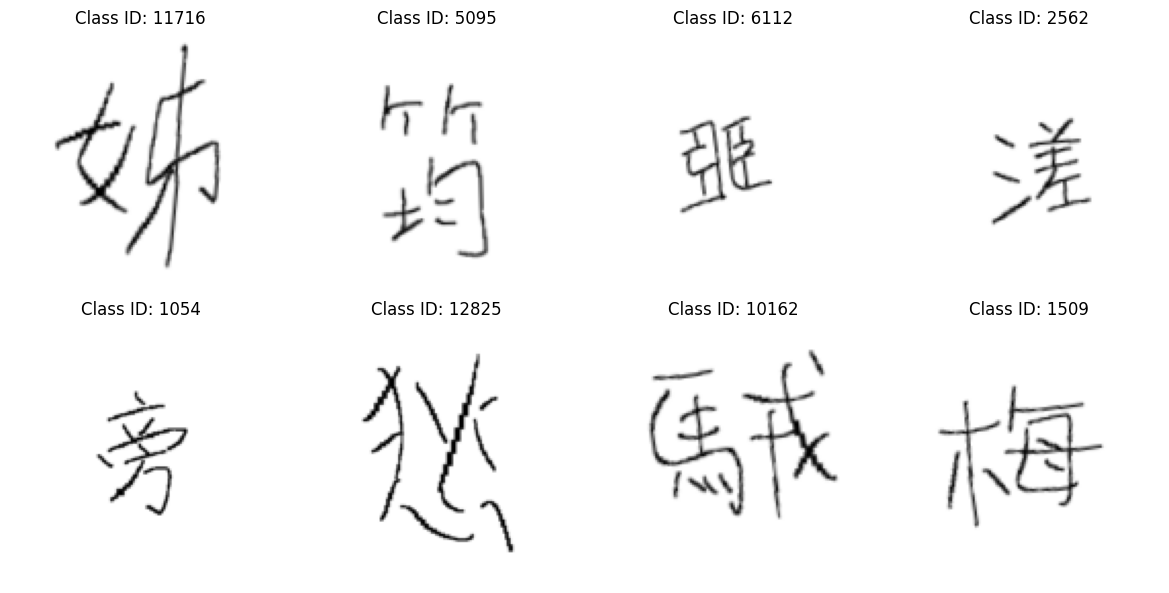

Batch image shape: (32, 128, 128, 1)
Batch label shape: (32,)
Training batches per epoch: 81657
GPU count: 0
The data pipeline is ready. No model training has started.


In [ ]:
import sys
import importlib
import matplotlib.pyplot as plt
import tensorflow as tf

PROJECT_PATH = "/content/DIT5411_project"

if PROJECT_PATH not in sys.path:
    sys.path.insert(0, PROJECT_PATH)

import training_core as core
importlib.reload(core)

frame, all_paths, plan = core.load_metadata()

train_ds = core.make_dataset(
    frame, all_paths, plan, "train", batch_size=32
)
validation_ds = core.make_dataset(
    frame, all_paths, plan, "validation", batch_size=32
)

images, labels = next(iter(train_ds))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for index, ax in enumerate(axes.ravel()):
    ax.imshow(images[index, ..., 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Class ID: {int(labels[index])}")
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    f"{PROJECT_PATH}/training_batch_preview.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Training batches per epoch:", int(train_ds.cardinality()))
print("GPU count:", len(tf.config.list_physical_devices("GPU")))
print("The data pipeline is ready. No model training has started.")

In [ ]:
import time
import tensorflow as tf

if not tf.config.list_physical_devices("GPU"):
    print("GPU unavailable: benchmark skipped.")
    print("Do not start full training on this CPU runtime.")
else:
    tf.keras.utils.set_random_seed(2026)
    benchmark_model = core.build_model("baseline")
    iterator = iter(train_ds.repeat())

    # Warm up tracing, GPU kernels, and optimizer variables.
    for _ in range(5):
        x, y = next(iterator)
        benchmark_model.train_on_batch(x, y)

    steps = 30
    start = time.perf_counter()

    for _ in range(steps):
        x, y = next(iterator)
        benchmark_model.train_on_batch(x, y)

    seconds_per_step = (time.perf_counter() - start) / steps
    batches = int(train_ds.cardinality())
    estimated_hours = seconds_per_step * batches / 3600

    print(f"Measured seconds per training batch: {seconds_per_step:.3f}")
    print(
        "Approximate baseline training time per full epoch: "
        f"{estimated_hours:.2f} hours"
    )
    print("This excludes validation, saving, and runtime interruptions.")
    print("Deep and residual models need separate timing.")
    print("Benchmark model discarded; no official result was recorded.")

    del benchmark_model

GPU unavailable: benchmark skipped.
Do not start full training on this CPU runtime.


In [ ]:
from pathlib import Path
import zipfile
from google.colab import files

project = Path("/content/DIT5411_project")
backup = Path("/content/DIT5411_latest_project.zip")

required = [
    "training_core.py",
    "class_mapping.json",
    "development_manifest.csv",
    "development_augmentation_plan.npz",
    "experiment_config.json"
]

for name in required:
    if not (project / name).is_file():
        raise FileNotFoundError(f"Missing project file: {name}")

with zipfile.ZipFile(
    backup, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in sorted(project.rglob("*")):
        if path.is_file():
            archive.write(
                path,
                arcname=(
                    Path("DIT5411_project") / path.relative_to(project)
                ).as_posix()
            )

print("Latest project backup:", backup)
print(f"Backup size: {backup.stat().st_size / 1024**2:.1f} MB")
files.download(str(backup))

Latest project backup: /content/DIT5411_latest_project.zip
Backup size: 19.3 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>